In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
from itertools import product
from collections import Counter
import os
from Bio.Seq import reverse_complement


In [3]:
output_path = '/home/nika/Documents/barpwml/genomes'
with open (output_path, 'r') as f:
    genomes = json.load(f)
print(f'reloaded {len(genomes)} genomes')

reloaded 95 genomes


In [4]:
def get_all_kmers(k):
    # Generate ALL possible k-mers for DNA alphabet.
    # This defines the fixed vocabulary — every genome gets score against the same list, even if some k-mers never appear
    bases = ['A', 'C', 'G', 'T']
    return [''.join(p) for p in product(bases, repeat=k)]

In [ ]:
def count_kmers(sequence, k=4, include_reverse_complement=True):
    """
    Count k-mer frequencies in a DNA sequence.

    Parameters:
        sequence: DNA string (uppercase)
        k: k-mer length
        include_reverse_complement: if True, also count the reverse strand

    Returns:
        dict mapping each possible k-mer to its relative frequency
    """

    # Remove N and any non-ATGC characters
    sequence = sequence.upper()
    sequence = ''.join(b for b in sequence if b in 'ATGC')

    if len(sequence) < k:
        raise ValueError(f'Sequence too short ({len(sequence)} bp for k={k}')

    # Build the complete vocabulary (all 4^k possible k-mers)
    vocabulary = get_all_kmers(k)
    counts = Counter({kmer: 0 for kmer in vocabulary})  # start all at 0

    # Count k-mers on the forward strand
    for i in range(len(sequence) - k + 1):
        kmer = sequence[i : i+k]
        if kmer in counts:
            counts[kmer] += 1
    
    # Count reverse complement strand too
    if include_reverse_complement:
        rev_comp = reverse_complement(sequence)
        for i in range(len(rev_comp) - k + 1):
            kmer = rev_comp[i : i+k]
            if kmer in counts:
                counts[kmer] += 1
    
    # Convert to relative frequencies
    total = sum(counts.values())
    frequencies = {kmer: counts[kmer] / total for kmer in vocabulary}
    
    return frequencies


In [15]:
def reverse_complement(sequence):
    # Return the reverse complement of a DNA sequence
    complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G'}
    return ''.join(complement[b] for b in reversed(sequence))


In [16]:
# Test
test_seq = "ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG"
freqs = count_kmers(test_seq, k=4)

print(f"Total k-mers in vocabulary: {len(freqs)}")
print(f"All frequencies sum to: {sum(freqs.values()):.6f}")

Total k-mers in vocabulary: 256
All frequencies sum to: 1.000000


In [17]:
print(freqs)

{'AAAA': 0.0, 'AAAC': 0.0, 'AAAG': 0.013888888888888888, 'AAAT': 0.0, 'AACA': 0.0, 'AACC': 0.0, 'AACG': 0.0, 'AACT': 0.0, 'AAGA': 0.0, 'AAGC': 0.0, 'AAGG': 0.013888888888888888, 'AAGT': 0.0, 'AATA': 0.0, 'AATC': 0.0, 'AATG': 0.027777777777777776, 'AATT': 0.0, 'ACAA': 0.013888888888888888, 'ACAC': 0.0, 'ACAG': 0.0, 'ACAT': 0.0, 'ACCA': 0.0, 'ACCC': 0.013888888888888888, 'ACCG': 0.0, 'ACCT': 0.0, 'ACGA': 0.0, 'ACGC': 0.0, 'ACGG': 0.0, 'ACGT': 0.0, 'ACTA': 0.0, 'ACTC': 0.0, 'ACTG': 0.0, 'ACTT': 0.0, 'AGAA': 0.0, 'AGAC': 0.0, 'AGAG': 0.0, 'AGAT': 0.0, 'AGCA': 0.0, 'AGCC': 0.0, 'AGCG': 0.013888888888888888, 'AGCT': 0.0, 'AGGA': 0.0, 'AGGC': 0.0, 'AGGG': 0.013888888888888888, 'AGGT': 0.0, 'AGTA': 0.0, 'AGTC': 0.0, 'AGTG': 0.0, 'AGTT': 0.0, 'ATAA': 0.0, 'ATAC': 0.0, 'ATAG': 0.013888888888888888, 'ATAT': 0.0, 'ATCA': 0.0, 'ATCC': 0.0, 'ATCG': 0.013888888888888888, 'ATCT': 0.0, 'ATGA': 0.0, 'ATGC': 0.0, 'ATGG': 0.041666666666666664, 'ATGT': 0.0, 'ATTA': 0.013888888888888888, 'ATTC': 0.0, 'ATTG'

In [18]:
test_genome = list(genomes.values())[0]
print(f'Genome length: {len(test_genome):,}bp/n ')

for k in [3, 4, 5, 6]:
    start = time.time()
    freqs = count_kmers(test_genome, k=k)
    elapsed = time.time() - start
    print(f'k={k}: {len(freqs):>5} features, computed in {elapsed: .2f}')

Genome length: 4,641,652bp/n 
k=3:    64 features, computed in  6.51
k=4:   256 features, computed in  6.45
k=5:  1024 features, computed in  6.46
k=6:  4096 features, computed in  7.00


In [20]:
from itertools import islice

# Peek at just 5 keys
sample_keys = list(islice(genomes.keys(), 5))
print("Sample keys:", sample_keys)

# Peek at key + value type and length/shape
for k, v in islice(genomes.items(), 5):
    size = len(v) if hasattr(v, "__len__") else "n/a"
    print(f"{k!r}: type={type(v).__name__}, len={size}")

Sample keys: ['GCA_000005845.2', 'GCF_048568945.1', 'GCA_048568925.1', 'GCF_048568975.1', 'GCF_048569005.1']
'GCA_000005845.2': type=str, len=4641652
'GCF_048568945.1': type=str, len=6125207
'GCA_048568925.1': type=str, len=5785358
'GCF_048568975.1': type=str, len=6060170
'GCF_048569005.1': type=str, len=5806684


In [21]:
first_key = next(iter(genomes))
val = genomes[first_key]
print("First key:", first_key)
print("Preview:", val[:100] if isinstance(val, (str, bytes, list, tuple)) else val)

First key: GCA_000005845.2
Preview: AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGCTTCTGAACTGGTTACCTGCCGTGAGTAAAT


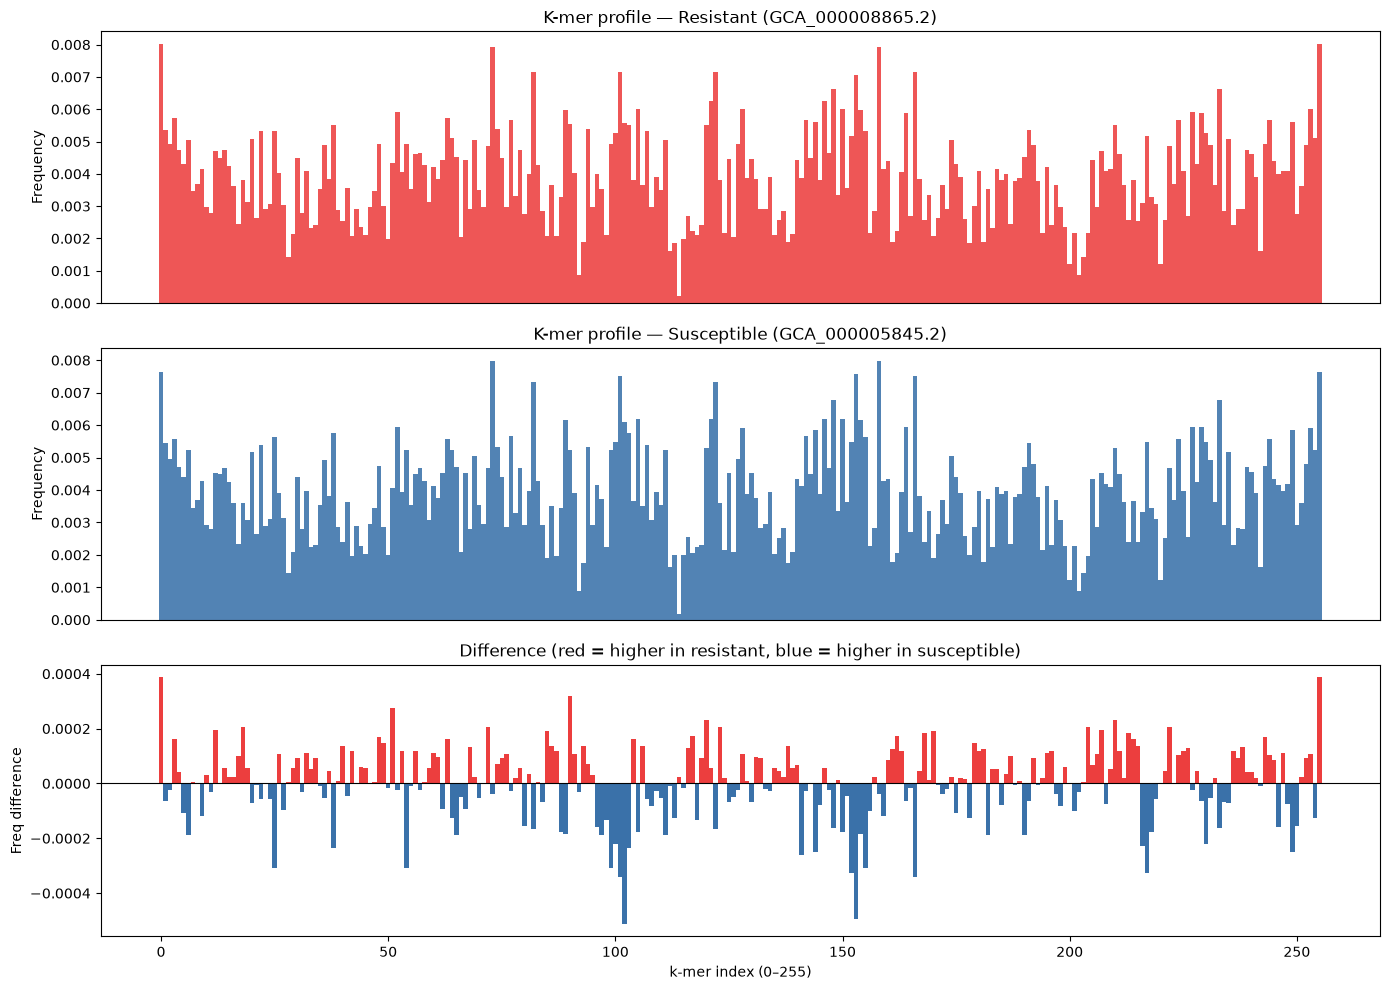


Top 10 most different k-mers between these two genomes:
  CGCG  diff=-0.00051
  GCGC  diff=-0.00049
  AAAA  diff=+0.00039
  TTTT  diff=+0.00039
  GGCG  diff=-0.00034
  CGCC  diff=-0.00034
  GCGA  diff=-0.00033
  TCGC  diff=-0.00033
  CCGG  diff=+0.00032
  GCGT  diff=-0.00031


In [23]:
labels_df = pd.read_csv("../data/cleaned_n_joined.csv", low_memory=False)

# Find one resistant and one susceptible genome ID
resistant_id = labels_df[labels_df["label"] == 1]["assembly_accession"].iloc[0]
susceptible_id = labels_df[labels_df["label"] == 0]["assembly_accession"].iloc[0]

k = 4
vocab = get_all_kmers(k)

r_freqs = count_kmers(genomes[str(resistant_id)], k=k)
s_freqs = count_kmers(genomes[str(susceptible_id)], k=k)

r_vals = [r_freqs[km] for km in vocab]
s_vals = [s_freqs[km] for km in vocab]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Panel 1: resistant profile
axes[0].bar(range(len(vocab)), r_vals, color="#E80E0E", alpha=0.7, width=1.0)
axes[0].set_title(f"K-mer profile — Resistant ({resistant_id})")
axes[0].set_ylabel("Frequency")
axes[0].set_xticks([])

# panel 2: susceptible profile
axes[1].bar(range(len(vocab)), s_vals, color="#084E94", alpha=0.7, width=1.0)
axes[1].set_title(f"K-mer profile — Susceptible ({susceptible_id})")
axes[1].set_ylabel("Frequency")
axes[1].set_xticks([])

# Panel 3: difference (which k-mers differ between the two)
diff = np.array(r_vals) - np.array(s_vals)
colors = ["#E80E0E" if d > 0 else "#084E94" for d in diff]
axes[2].bar(range(len(vocab)), diff, color=colors, alpha=0.8, width=1.0)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_title("Difference (red = higher in resistant, blue = higher in susceptible)")
axes[2].set_ylabel("Freq difference")
axes[2].set_xlabel("k-mer index (0–255)")

plt.tight_layout()
plt.savefig("../plots/kmer_profiles_comparison.png", dpi=500, bbox_inches='tight')
plt.show()

# Find the most discriminating k-mers
top_diff_indices = np.argsort(np.abs(diff))[-10:][::-1]
print("\nTop 10 most different k-mers between these two genomes:")
for idx in top_diff_indices:
    print(f"  {vocab[idx]}  diff={diff[idx]:+.5f}")


In [ ]:
# Compute kmer frequency
k = 4
vocab = get_all_kmers(k)
all_features = {}
errors = []

print(f"Computing {k}-mer frequencies for {len(genomes)} genomes...\n")
start_total = time.time()

for i, (genome_id, sequence) in enumerate(genomes.items()):
    try:
        freqs = count_kmers(sequence, k=k)
        all_features[genome_id] = [freqs[km] for km in vocab]
        
        if (i + 1) % 10 == 0:
            elapsed = time.time() - start_total
            print(f"  {i+1}/{len(genomes)} done  ({elapsed:.1f}s elapsed)")
    
    except Exception as e:
        print(f"  ERROR on {genome_id}: {e}")
        errors.append(genome_id)

print(f"\nDone. {len(all_features)} succeeded, {len(errors)} failed.")
if errors:
    print(f"Failed genomes: {errors}")



Computing 4-mer frequencies for 95 genomes...

  10/95 done  (40.1s elapsed)
  20/95 done  (80.7s elapsed)
  30/95 done  (121.3s elapsed)
  40/95 done  (162.6s elapsed)
  50/95 done  (202.7s elapsed)
  60/95 done  (242.7s elapsed)
  70/95 done  (283.0s elapsed)
  80/95 done  (324.0s elapsed)
  90/95 done  (364.1s elapsed)

Done. 95 succeeded, 0 failed.


In [ ]:
# Save feature matrix and vocabulary
feature_ids = list(all_features.keys())

# Build the numpy array
feature_matrix = np.array([all_features[gid] for gid in feature_ids])

np.save('../features/kmer_matrix.npy', feature_matrix)

with open('../features/kmer_metadata.json', 'w') as f:
    json.dump({"genome_ids": feature_ids, "vocab": vocab, "k": k}, f)


print(f"Saved feature matrix: {feature_matrix.shape}")
print(f"  Rows = genomes: {feature_matrix.shape[0]}")
print(f"  Cols = k-mers:  {feature_matrix.shape[1]}")

Saved feature matrix: (95, 256)
  Rows = genomes: 95
  Cols = k-mers:  256


In [27]:
label_ids = set(labels_df["assembly_accession"].astype(str))

feature_ids = set(feature_ids)
shared_ids = feature_ids & label_ids

print(f"Genomes with features:       {len(feature_ids)}")
print(f"Genomes with labels:         {len(label_ids)}")
print(f"Genomes with BOTH:           {len(shared_ids)}")
print(f"Features but no label:       {len(feature_ids - label_ids)}")
print(f"Labels but no genome/feature:{len(label_ids - feature_ids)}")

print(f"\nSample feature IDs: {list(feature_ids)[:3]}")
print(f"Sample label IDs:   {list(label_ids)[:3]}")

Genomes with features:       95
Genomes with labels:         100
Genomes with BOTH:           95
Features but no label:       0
Labels but no genome/feature:5

Sample feature IDs: ['GCF_003018455.1', 'GCA_003018455.1', 'GCA_027925565.1']
Sample label IDs:   ['GCF_003018455.1', 'GCA_003018455.1', 'GCA_027925565.1']


In [29]:
sorted_ids = sorted(shared_ids)
print(f"Building matrix from {len(sorted_ids)} genomes")

original_id_list = list(feature_ids)
id_to_row_index = {
    genome_id: index for index, genome_id in enumerate(original_id_list)
}

sorted_row_indices = [id_to_row_index[genome_id] for genome_id in sorted_ids]

X = feature_matrix[sorted_row_indices].astype(np.float32)

label_lookup = labels_df.set_index("assembly_accession")["label"]
label_lookup.index = label_lookup.index.astype(str)

y_vals = []
for genome_id in sorted_ids:
    val = label_lookup.loc[genome_id]

    if isinstance(val, pd.Series):
        y_vals.append(val.iloc[0])
    else:
        y_vals.append(val)

y = np.array(y_vals, dtype=np.int32)

print(f"\nX shape: {X.shape}  (rows=genomes, cols=k-mers)")
print(f"y shape: {y.shape}")

unique_classes, counts = np.unique(y, return_counts=True)
print(f"y values breakdown: {dict(zip(unique_classes, counts))}")

Building matrix from 95 genomes

X shape: (95, 256)  (rows=genomes, cols=k-mers)
y shape: (95,)
y values breakdown: {np.int32(0): np.int64(70), np.int32(1): np.int64(25)}


In [30]:
print("Alignment spot check\n")
print(f"{'Index':<6} {'assembly_accession':<25} {'Label':<10} {'Feature sum':<15} {'First 3 features'}")
print("-" * 75)

for i in [0, 1, 2, -3, -2, -1]:  # checking first 3 and last 3
    gid = sorted_ids[i]
    label = y[i]
    feat_sum = X[i].sum()
    first3 = X[i][:3].round(5)
    print(f"{i:<6} {gid:<25} {label:<10} {feat_sum:<15.6f} {first3}")

#  Relative frequencies
row_sums = X.sum(axis=1)
print(f"\nRow sum stats (should all be ~1.0):")
print(f"  Min: {row_sums.min():.6f}")
print(f"  Max: {row_sums.max():.6f}")
print(f"  Mean: {row_sums.mean():.6f}")

Alignment spot check

Index  assembly_accession        Label      Feature sum     First 3 features
---------------------------------------------------------------------------
0      GCA_000005845.2           0          1.000000        [0.00791 0.00535 0.00488]
1      GCA_000008865.2           1          1.000000        [0.00773 0.00534 0.00484]
2      GCA_000010385.1           0          1.000000        [0.00794 0.00535 0.00489]
-3     GCF_051012485.1           1          1.000000        [0.00792 0.00535 0.0049 ]
-2     GCF_053078305.1           1          1.000000        [0.00774 0.00539 0.00493]
-1     GCF_055379255.1           1          1.000000        [0.00792 0.00535 0.0049 ]

Row sum stats (should all be ~1.0):
  Min: 1.000000
  Max: 1.000000
  Mean: 1.000000


Resistant:   25 (26.3%)
Susceptible: 70 (73.7%)


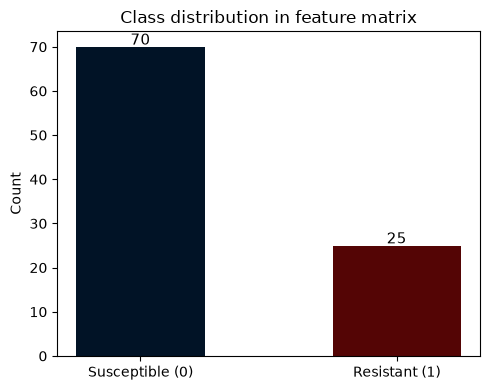


Use class_weight='balanced' in your model at Stage 6.


In [32]:
n_resistant   = (y == 1).sum()
n_susceptible = (y == 0).sum()
total = len(y)

print(f"Resistant:   {n_resistant} ({n_resistant/total:.1%})")
print(f"Susceptible: {n_susceptible} ({n_susceptible/total:.1%})")

# Visualization
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Susceptible (0)", "Resistant (1)"],
              [n_susceptible, n_resistant],
              color=["#011326", "#540505"], width=0.5)

for bar, count in zip(bars, [n_susceptible, n_resistant]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            str(count), ha="center", fontsize=11)

ax.set_title("Class distribution in feature matrix")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig('../plots/class_distribution.png', dpi=500, bbox_inches = 'tight')
plt.show()

# Flag imbalance
ratio = min(n_resistant, n_susceptible) / max(n_resistant, n_susceptible)
if ratio < 0.5:
    print(f"\nWARNING: imbalanced classes (ratio={ratio:.2f})")
    print("Use class_weight='balanced' in your model at Stage 6.")
else:
    print(f"\nClass balance OK (ratio={ratio:.2f})")